In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import warnings

warnings.filterwarnings('ignore')

In [2]:
class MNIST_Reducer(object):
    def __init__(self, n_samples=10000):
        print("Загрузка датасета MNIST (это может занять около минуты)...")
        # Загружаем датасет напрямую через sklearn
        mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')

        # Берем подвыборку для ускорения работы t-SNE
        np.random.seed(42)
        idx = np.random.choice(len(mnist.data), n_samples, replace=False)

        # Нормализуем пиксели (от 0 до 1)
        self.X = mnist.data[idx] / 255.0
        self.y = mnist.target[idx].astype(int)

        self.X_pca = None
        self.X_tsne_2d = None
        self.X_tsne_3d = None

        print(f"Данные успешно загружены! Размерность выборки: {self.X.shape}")

    def apply_pca(self, variance=0.95):
        """1. Понижение размерности с помощью PCA (по умолчанию 95% дисперсии)"""
        print(f"\nПрименение PCA (сохранение {variance*100}% дисперсии)...")
        self.pca = PCA(n_components=variance, random_state=42)
        self.X_pca = self.pca.fit_transform(self.X)

        print(f"Исходная размерность признаков: {self.X.shape[1]}")
        print(f"Размерность после PCA: {self.X_pca.shape[1]}")
        print(f"Количество выбранных компонент PCA: {self.pca.n_components_}")

    def apply_tsne(self):
        """2. Применение t-SNE (n_components = 2 и 3) к данным после PCA"""
        if self.X_pca is None:
            print("Сначала необходимо запустить метод apply_pca()!")
            return

        print("\nЗапуск t-SNE (2 компоненты)... Ожидайте, это займет некоторое время.")
        tsne_2d = TSNE(n_components=2, random_state=42, n_jobs=-1)
        self.X_tsne_2d = tsne_2d.fit_transform(self.X_pca)

        print("Запуск t-SNE (3 компоненты)...")
        tsne_3d = TSNE(n_components=3, random_state=42, n_jobs=-1)
        self.X_tsne_3d = tsne_3d.fit_transform(self.X_pca)
        print("Преобразование t-SNE завершено!")

    def visualize(self):
        """3. Визуализация полученных результатов в 2D и 3D"""
        if self.X_tsne_2d is None or self.X_tsne_3d is None:
            print("Сначала необходимо запустить метод apply_tsne()!")
            return

        fig = plt.figure(figsize=(18, 8))

        # --- 2D Визуализация ---
        ax1 = fig.add_subplot(121)
        scatter1 = ax1.scatter(self.X_tsne_2d[:, 0], self.X_tsne_2d[:, 1],
                               c=self.y, cmap='tab10', alpha=0.7, s=15)
        ax1.set_title('t-SNE: 2 компоненты (после PCA)')
        ax1.set_xlabel('t-SNE Component 1')
        ax1.set_ylabel('t-SNE Component 2')
        # Добавляем цветовую шкалу с цифрами от 0 до 9
        cbar1 = fig.colorbar(scatter1, ax=ax1, ticks=range(10))
        cbar1.set_label('Классы (Цифры)')

        # --- 3D Визуализация ---
        ax2 = fig.add_subplot(122, projection='3d')
        scatter2 = ax2.scatter(self.X_tsne_3d[:, 0], self.X_tsne_3d[:, 1], self.X_tsne_3d[:, 2],
                               c=self.y, cmap='tab10', alpha=0.7, s=15)
        ax2.set_title('t-SNE: 3 компоненты (после PCA)')
        ax2.set_xlabel('Component 1')
        ax2.set_ylabel('Component 2')
        ax2.set_zlabel('Component 3')

        plt.tight_layout()
        plt.show()

Загрузка датасета MNIST (это может занять около минуты)...
Данные успешно загружены! Размерность выборки: (10000, 784)

Применение PCA (сохранение 95.0% дисперсии)...
Исходная размерность признаков: 784
Размерность после PCA: 151
Количество выбранных компонент PCA: 151

Запуск t-SNE (2 компоненты)... Ожидайте, это займет некоторое время.
Запуск t-SNE (3 компоненты)...
Преобразование t-SNE завершено!


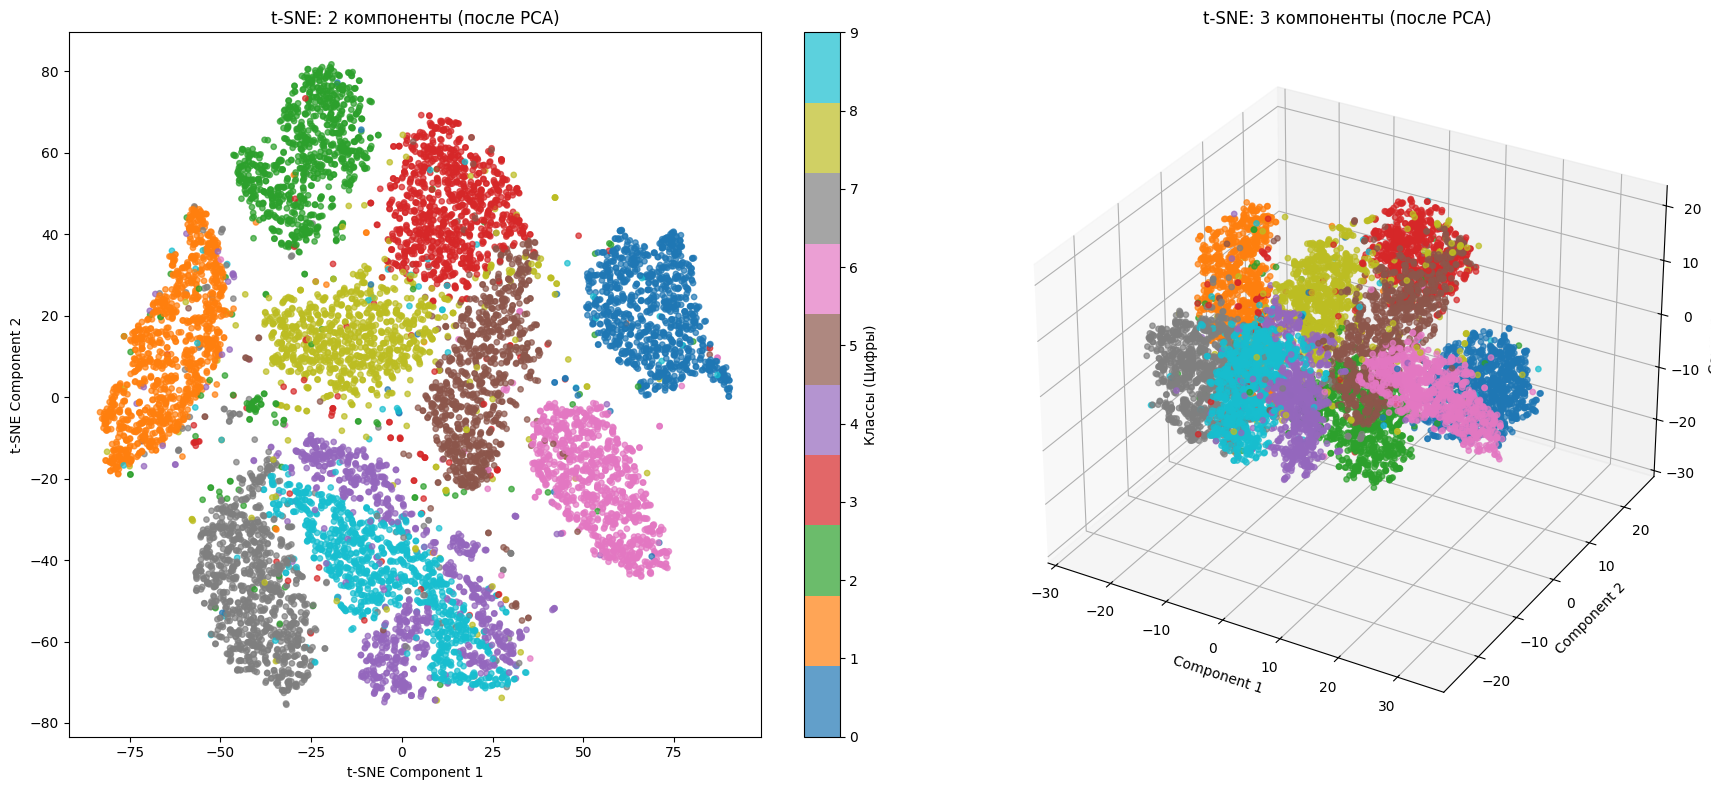

In [3]:
# Инициализация класса с 10000 примерами (можно изменить)
mnist_model = MNIST_Reducer(n_samples=10000)

# Шаг 1: Применяем PCA с сохранением 95% дисперсии
mnist_model.apply_pca(variance=0.95)

# Шаг 2: Применяем t-SNE для 2 и 3 компонент на сжатых данных
mnist_model.apply_tsne()

# Шаг 3: Отрисовываем 2D и 3D графики
mnist_model.visualize()